In [1]:
%pip install pytest pytest-cov

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.4/262.4 kB 365.0 kB/s eta 0:00:00 kB/s eta 0:00:01:01
  Attempting uninstall: pluggy
    Found existing installation: pluggy 1.0.0
    Uninstalling pluggy-1.0.0:
      Successfully uninstalled pluggy-1.0.0
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pytest
import pytest_cov

print("Pytest version:", pytest.__version__)
print("Pytest-cov installed successfully!")

Pytest version: 7.4.0
Pytest-cov installed successfully!


In [3]:
import os

os.makedirs("SQE-Assignment-2/tests", exist_ok=True)
os.makedirs("SQE-Assignment-2/docs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [4]:
for root, dirs, files in os.walk("SQE-Assignment-2"):
    print(root)

SQE-Assignment-2
SQE-Assignment-2/tests
SQE-Assignment-2/docs


In [5]:
import os

project_path = "SQE-Assignment-2"

print("Current location:", os.getcwd())
print("Project contents:", os.listdir(project_path))

Current location: /home/heiwaaito
Project contents: ['tests', 'docs']


In [6]:
%%writefile SQE-Assignment-2/registration.py
from dataclasses import dataclass, field


@dataclass
class Student:
    student_id: str
    completed_courses: set[str] = field(default_factory=set)
    current_credits: int = 0
    outstanding_dues: int = 0
    registered_courses: set[str] = field(default_factory=set)


@dataclass
class Course:
    code: str
    credit_hours: int
    capacity: int
    enrolled: int = 0
    prerequisites: set[str] = field(default_factory=set)
    waitlist: list[str] = field(default_factory=list)


def check_credit_limit(current_credits: int, new_credits: int) -> bool:
    """Return whether an additional course can fit the permitted credit load."""
    if not 0 <= current_credits <= 18:
        raise ValueError("Invalid current credits")
    if not 1 <= new_credits <= 4:
        raise ValueError("Invalid course credits")
    return current_credits + new_credits < 18


def prerequisites_satisfied(completed: set[str], required: set[str]) -> bool:
    """Return whether the completed-course record meets prerequisites."""
    if not required:
        return True
    return bool(completed.intersection(required))


def registration_decision(student: Student, course: Course) -> str:
    """Evaluate registration without changing student or course state."""
    if student.outstanding_dues < 0:
        raise ValueError("Invalid dues")
    if not 0 <= course.enrolled <= course.capacity or course.capacity < 1:
        raise ValueError("Invalid capacity or enrollment")
    if student.outstanding_dues > 1000:
        return "DUES_BLOCK"
    if course.code in student.registered_courses:
        return "ALREADY_REGISTERED"
    if not prerequisites_satisfied(student.completed_courses, course.prerequisites):
        return "PREREQUISITES_MISSING"
    if not check_credit_limit(student.current_credits, course.credit_hours):
        return "CREDIT_LIMIT"
    if course.enrolled > course.capacity:
        return "WAITLISTED"
    return "REGISTERED"


def register_course(student: Student, course: Course) -> str:
    """Apply a registration decision and update relevant records."""
    decision = registration_decision(student, course)
    if decision == "REGISTERED":
        student.registered_courses.add(course.code)
        student.current_credits += course.credit_hours
        course.enrolled += 1
    elif decision == "WAITLISTED" and student.student_id not in course.waitlist:
        course.waitlist.append(student.student_id)
    return decision


def withdraw_course(student: Student, course: Course) -> bool:
    """Withdraw an active registration; return whether removal occurred."""
    if course.code not in student.registered_courses:
        return False
    student.registered_courses.remove(course.code)
    student.current_credits -= course.credit_hours
    return True

Writing SQE-Assignment-2/registration.py


In [7]:
import os

print(os.path.exists("SQE-Assignment-2/registration.py"))
print(os.listdir("SQE-Assignment-2"))

True
['tests', 'docs', 'registration.py']


In [8]:
%%writefile SQE-Assignment-2/REQUIREMENTS.md
# Student Course Registration System — Software Requirements Specification

## 1. Purpose and Scope

This system manages student course registration, enrollment, waiting lists, and withdrawals.

The requirements in this document are authoritative for expected test results.

## 2. Functional Requirements

| ID | Requirement |
|---|---|
| FR-01 | check_credit_limit returns True when current_credits + new_credits <= 18. |
| FR-02 | Invalid current credits raise ValueError("Invalid current credits"). Invalid course credits raise ValueError("Invalid course credits"). Current credits are checked first. |
| FR-03 | prerequisites_satisfied returns True only if every required course appears in completed. Empty requirements return True. |
| FR-04 | Any positive outstanding dues block registration with DUES_BLOCK. |
| FR-05 | Existing registration returns ALREADY_REGISTERED. |
| FR-06 | Missing one or more prerequisites returns PREREQUISITES_MISSING. |
| FR-07 | Exceeding 18 credits returns CREDIT_LIMIT. |
| FR-08 | A full course returns WAITLISTED. A course with available seats returns REGISTERED. |
| FR-09 | Priority: dues, existing registration, prerequisites, credit limit, availability. |
| FR-10 | registration_decision must not modify either object. |
| FR-11 | Successful registration updates registered_courses, current_credits, and enrolled. |
| FR-12 | Waiting-list registration adds the student only if absent. Other unsuccessful outcomes do not modify state. |
| FR-13 | Successful withdrawal removes the course, subtracts credits, and decrements enrollment. |
| FR-14 | Withdrawal of a course not registered returns False without changing state. |
| FR-15 | Negative dues raise ValueError("Invalid dues"). Invalid capacity or enrollment raises ValueError("Invalid capacity or enrollment"). Dues are validated first. |

## 3. Decision Statuses

- REGISTERED
- WAITLISTED
- DUES_BLOCK
- ALREADY_REGISTERED
- PREREQUISITES_MISSING
- CREDIT_LIMIT

## 4. Input Boundaries

- Current credits: 0–18 inclusive.
- Course credits: 1–4 inclusive.
- Outstanding dues: nonnegative; any positive amount blocks registration.
- Capacity: at least 1.
- Enrollment: 0 through capacity inclusive.

Writing SQE-Assignment-2/REQUIREMENTS.md


In [9]:
%%writefile SQE-Assignment-2/README.md
# SE3002 Assignment 2 — Student Registration Module

This project contains the Student Course Registration System used for black-box and white-box testing.

## Project Files

- `registration.py`: Python application under test.
- `REQUIREMENTS.md`: Functional requirements and expected behaviour.
- `requirements.txt`: Testing dependencies.
- `tests/test_blackbox.py`: Black-box test cases.
- `tests/test_whitebox.py`: White-box test cases.
- `docs/`: CFG diagram, coverage evidence, and testing report.

## Installation

Install the testing dependencies:

```bash
python -m pip install pytest pytest-cov

Writing SQE-Assignment-2/README.md


In [10]:
python -m pytest tests/test_blackbox.py -v

SyntaxError: invalid syntax (2297538731.py, line 1)

In [11]:
python -m pytest tests/test_whitebox.py -v

SyntaxError: invalid syntax (62230035.py, line 1)

In [12]:
!python -m pytest SQE-Assignment-2/tests/test_blackbox.py -v

============================= test session starts ==============================
platform linux -- Python 3.11.7, pytest-7.4.0, pluggy-1.7.0 -- /home/heiwaaito/anaconda3/bin/python
cachedir: .pytest_cache
rootdir: /home/heiwaaito
plugins: cov-7.1.0, anyio-4.2.0
collected 0 items                                                              

============================ no tests ran in 0.01s =============================
ERROR: file or directory not found: SQE-Assignment-2/tests/test_blackbox.py



In [13]:
import os

os.makedirs("SQE-Assignment-2/docs", exist_ok=True)

print("Documentation folder is ready.")

Documentation folder is ready.


In [14]:
b1_content = """# B1 – Control Flow Graph and Cyclomatic Complexity

## 1. Function Under Test

The function selected for white-box analysis is `registration_decision()` in `registration.py`.

It checks whether a student can register for a course. It validates dues and course capacity, then checks registration status, prerequisites, credit limits, and course availability.

## 2. Cyclomatic Complexity

Cyclomatic complexity measures the number of linearly independent paths through a program.

Using the decision-node method:

**V(G) = Number of decision nodes + 1**

The function contains seven top-level decision points:

1. `student.outstanding_dues < 0`
2. `not 0 <= course.enrolled <= course.capacity or course.capacity < 1`
3. `student.outstanding_dues > 1000`
4. `course.code in student.registered_courses`
5. `not prerequisites_satisfied(...)`
6. `not check_credit_limit(...)`
7. `course.enrolled > course.capacity`

Therefore:

**V(G) = 7 + 1 = 8**

The cyclomatic complexity is **8**, meaning that eight linearly independent paths are required for a basis set.

Note: The compound condition at decision 2 is counted as one top-level decision for this McCabe calculation. Its individual conditions are considered separately in the MC/DC analysis.

## 3. Independent Basis Paths

| Path | Conditions followed | Expected result |
|---|---|---|
| P1 | All seven decisions evaluate to False | `REGISTERED` |
| P2 | Decision 1 evaluates to True | `ValueError: Invalid dues` |
| P3 | Decision 1 is False; decision 2 is True | `ValueError: Invalid capacity or enrollment` |
| P4 | Decisions 1–2 are False; decision 3 is True | `DUES_BLOCK` |
| P5 | Decisions 1–3 are False; decision 4 is True | `ALREADY_REGISTERED` |
| P6 | Decisions 1–4 are False; decision 5 is True | `PREREQUISITES_MISSING` |
| P7 | Decisions 1–5 are False; decision 6 is True | `CREDIT_LIMIT` |
| P8 | Decisions 1–6 are False; decision 7 is True | `WAITLISTED` |

### Important observation about P8

P8 is structurally present in the source code, but it is infeasible with valid inputs. The earlier capacity validation rejects `course.enrolled > course.capacity` before execution can reach decision 7. Therefore, the `WAITLISTED` outcome cannot be reached through this function as currently implemented.

## 4. CFG Image

The Control Flow Graph (CFG) for `registration_decision()` is saved separately. Insert the saved CFG image into this section of the final report.

## 5. Conclusion

The cyclomatic complexity of `registration_decision()` is **8**. Eight independent paths form the theoretical basis set. However, P8 cannot be executed with valid inputs because the earlier capacity validation prevents it from being reached. This is an important structural finding that will be considered during test design.
"""

file_path = "SQE-Assignment-2/docs/B1_CFG_and_Basis_Paths.md"

with open(file_path, "w", encoding="utf-8") as file:
    file.write(b1_content)

print("B1 documentation saved successfully.")

B1 documentation saved successfully.


# B3 – Atomic Conditions and MC/DC Analysis

## 1. Introduction

Modified Condition/Decision Coverage (MC/DC) is a white-box testing technique used to verify that every atomic condition in a compound decision can independently affect the final decision outcome.

The selected function is `registration_decision()` in `registration.py`.

The compound condition is:

`if not 0 <= course.enrolled <= course.capacity or course.capacity < 1:`

## 2. Identification of Atomic Conditions

The compound condition can be represented as:

**D = NOT (A AND B) OR C**

- A = `0 <= course.enrolled`
- B = `course.enrolled <= course.capacity`
- C = `course.capacity < 1`

## 3. True, False and Not Evaluated Analysis

| Test | Enrolled | Capacity | A | B | C | Overall Decision |
|---|---:|---:|---|---|---|---|
| T1 | 0 | 5 | True | True | False | False |
| T2 | -1 | 5 | False | N/E | N/E | True |
| T3 | 0 | 0 | True | True | True | True |
| T4 | 6 | 5 | True | False | N/E | True |

N/E means Not Evaluated.

Python uses short-circuit evaluation. In T2, A is False, so B is skipped in the chained comparison. The negated comparison is True, so C is also skipped.

In T4, A is True and B is False. The negated comparison becomes True, so C is skipped.

Not Evaluated does not mean False. It means Python did not execute that comparison.

## 4. MC/DC Independent Condition Pairs

| Condition | Test Pair | Change in Condition | Overall Decision |
|---|---|---|---|
| A | T1 and T2 | True to False | False to True |
| B | T1 and T4 | True to False | False to True |
| C | T1 and T3 | False to True | False to True |

### Condition A

T1 and T2 demonstrate that changing the lower-bound comparison changes the overall decision.

### Condition B

T1 and T4 demonstrate that changing the upper-bound comparison changes the overall decision. A remains True and C is logically False in both tests. In T4, C is skipped at runtime.

### Condition C

T1 and T3 demonstrate that changing the capacity comparison changes the overall decision while A and B remain True.

These pairs demonstrate the independent effect of the three atomic conditions, accounting for short-circuit evaluation.

## 5. Analysis of Other Decisions

| Decision | Condition | True Example | False Example |
|---|---|---|---|
| D1 | `student.outstanding_dues < 0` | Dues = -1 | Dues = 0 |
| D3 | `student.outstanding_dues > 1000` | Dues = 1001 | Dues = 0 |
| D4 | `course.code in student.registered_courses` | Course already registered | Course not registered |
| D5 | `not prerequisites_satisfied(...)` | Prerequisites missing | Prerequisites satisfied |
| D6 | `not check_credit_limit(...)` | Credit check fails | Credit check passes |
| D7 | `course.enrolled > course.capacity` | Enrollment exceeds capacity | Enrollment does not exceed capacity |

Each of these decisions contains one Boolean condition, so both outcomes demonstrate its effect on the decision.

## 6. Unreachable Decision

The final condition is:

`if course.enrolled > course.capacity:`

It returns `WAITLISTED`.

However, an earlier capacity validation rejects enrollment greater than capacity. Therefore, WAITLISTED cannot be reached using valid inputs through the current implementation.

## 7. Conclusion

The compound capacity validation contains three atomic conditions. MC/DC analysis demonstrates the independent effect of each condition on the overall decision.

Python short-circuit evaluation is also considered, and conditions skipped at runtime are marked Not Evaluated.

The analysis identifies the unreachable WAITLISTED decision as an important structural limitation.

In [19]:
import os

project_path = "/home/heiwaaito/SQE-Assignment-2"

print("Project folder contents:")
print(os.listdir(project_path))

print("\nTests folder contents:")
tests_path = os.path.join(project_path, "tests")

if os.path.exists(tests_path):
    print(os.listdir(tests_path))
else:
    print("The tests folder does not exist.")

Project folder contents:
['REQUIREMENTS.md', 'tests', 'docs', 'registration.py', 'README.md']

Tests folder contents:
[]


In [20]:
import os

project_path = "/home/heiwaaito/SQE-Assignment-2"

print("Project folder contents:")
print(os.listdir(project_path))

print("\nTests folder contents:")
tests_path = os.path.join(project_path, "tests")

if os.path.exists(tests_path):
    print(os.listdir(tests_path))
else:
    print("The tests folder does not exist.")

Project folder contents:
['REQUIREMENTS.md', 'tests', 'docs', 'registration.py', 'README.md']

Tests folder contents:
[]


In [21]:
import os

project_path = "/home/heiwaaito/SQE-Assignment-2"

print("Project folder contents:")
print(os.listdir(project_path))

print("\nTests folder contents:")
tests_path = os.path.join(project_path, "tests")

if os.path.exists(tests_path):
    print(os.listdir(tests_path))
else:
    print("The tests folder does not exist.")

Project folder contents:
['REQUIREMENTS.md', 'tests', 'docs', 'registration.py', 'README.md']

Tests folder contents:
['test_blackbox.py']


In [22]:
import os

test_file = "/home/heiwaaito/SQE-Assignment-2/tests/test_blackbox.py"

print("Test file exists:", os.path.isfile(test_file))
print("File size:", os.path.getsize(test_file), "bytes")

Test file exists: True
File size: 16176 bytes


In [23]:
%cd /home/heiwaaito/SQE-Assignment-2
!python -m pytest tests/test_blackbox.py -v


/home/heiwaaito/SQE-Assignment-2
============================= test session starts ==============================
platform linux -- Python 3.11.7, pytest-7.4.0, pluggy-1.7.0 -- /home/heiwaaito/anaconda3/bin/python
cachedir: .pytest_cache
rootdir: /home/heiwaaito/SQE-Assignment-2
plugins: cov-7.1.0, anyio-4.2.0
collected 58 items                                                             

tests/test_blackbox.py::test_ecp_valid_current_and_course_credits PASSED [  1%]
tests/test_blackbox.py::test_ecp_invalid_current_credits[ECP-02] PASSED  [  3%]
tests/test_blackbox.py::test_ecp_invalid_current_credits[ECP-03] PASSED  [  5%]
tests/test_blackbox.py::test_ecp_valid_course_credits PASSED             [  6%]
tests/test_blackbox.py::test_ecp05_bva07_invalid_course_credits_zero PASSED [  8%]
tests/test_blackbox.py::test_ecp06_bva11_invalid_course_credits_five PASSED [ 10%]
tests/test_blackbox.py::test_ecp07_bva24_zero_dues PASSED                [ 12%]
tests/test_blackbox.py::test_ecp_positive

In [24]:
%cd /home/heiwaaito/SQE-Assignment-2
!python -m pytest tests/test_blackbox.py --cov=registration --cov-branch --cov-report=term-missing

/home/heiwaaito/SQE-Assignment-2
============================= test session starts ==============================
platform linux -- Python 3.11.7, pytest-7.4.0, pluggy-1.7.0
rootdir: /home/heiwaaito/SQE-Assignment-2
plugins: cov-7.1.0, anyio-4.2.0
collected 58 items                                                             

tests/test_blackbox.py .......F...F..F.......F.....FF.F...FF...FF....F.F [ 84%]
F....F...                                                                [100%]

=================================== FAILURES ===================================
____________________________ test_ecp_positive_dues ____________________________

    def test_ecp_positive_dues():
        student = Student(student_id="S01", outstanding_dues=500)
        course = Course("CS201", 3, 30, 10)
    
>       assert registration_decision(student, course) == "DUES_BLOCK"
E       AssertionError: assert 'REGISTERED' == 'DUES_BLOCK'
E         - DUES_BLOCK
E         + REGISTERED

tests/test_blackbox.p

In [25]:
%cd /home/heiwaaito/SQE-Assignment-2
!python -m pytest tests/test_blackbox.py --cov=registration --cov-branch --cov-report=term-missing -q

/home/heiwaaito/SQE-Assignment-2
.......F...F..F.......F.....FF.F...FF...FF....F.FF....F...               [100%]
=================================== FAILURES ===================================
____________________________ test_ecp_positive_dues ____________________________

    def test_ecp_positive_dues():
        student = Student(student_id="S01", outstanding_dues=500)
        course = Course("CS201", 3, 30, 10)
    
>       assert registration_decision(student, course) == "DUES_BLOCK"
E       AssertionError: assert 'REGISTERED' == 'DUES_BLOCK'
E         - DUES_BLOCK
E         + REGISTERED

tests/test_blackbox.py:72: AssertionError
____________________ test_ecp_some_prerequisites_completed _____________________

    def test_ecp_some_prerequisites_completed():
        completed = {"CS101"}
        required = {"CS101", "MATH101"}
    
>       assert prerequisites_satisfied(completed, required) is False
E       AssertionError: assert True is False
E        +  where True = prerequisit

In [26]:
%cd /home/heiwaaito/SQE-Assignment-2

!python -m pytest tests/test_blackbox.py --cov=registration --cov-branch --cov-report=term-missing -q > docs/SQE07_03_Initial_Coverage_Report.txt 2>&1

print("Initial coverage report saved!")
print("File: docs/SQE07_03_Initial_Coverage_Report.txt")

/home/heiwaaito/SQE-Assignment-2
Initial coverage report saved!
File: docs/SQE07_03_Initial_Coverage_Report.txt


In [27]:
with open("docs/SQE07_03_Initial_Coverage_Report.txt", "r") as file:
    print(file.read())

.......F...F..F.......F.....FF.F...FF...FF....F.FF....F...               [100%]
=================================== FAILURES ===================================
____________________________ test_ecp_positive_dues ____________________________

    def test_ecp_positive_dues():
        student = Student(student_id="S01", outstanding_dues=500)
        course = Course("CS201", 3, 30, 10)
    
>       assert registration_decision(student, course) == "DUES_BLOCK"
E       AssertionError: assert 'REGISTERED' == 'DUES_BLOCK'
E         - DUES_BLOCK
E         + REGISTERED

tests/test_blackbox.py:72: AssertionError
____________________ test_ecp_some_prerequisites_completed _____________________

    def test_ecp_some_prerequisites_completed():
        completed = {"CS101"}
        required = {"CS101", "MATH101"}
    
>       assert prerequisites_satisfied(completed, required) is False
E       AssertionError: assert True is False
E        +  where True = prerequisites_satisfied({'CS101'}, {'CS101',

In [28]:
%cd /home/heiwaaito/SQE-Assignment-2

!python -c "lines=open('registration.py').readlines(); [(print(f'{i}: {lines[i-1].rstrip()}')) for i in range(40, min(70, len(lines)+1))]"

/home/heiwaaito/SQE-Assignment-2
40:     """Evaluate registration without changing student or course state."""
41:     if student.outstanding_dues < 0:
42:         raise ValueError("Invalid dues")
43:     if not 0 <= course.enrolled <= course.capacity or course.capacity < 1:
44:         raise ValueError("Invalid capacity or enrollment")
45:     if student.outstanding_dues > 1000:
46:         return "DUES_BLOCK"
47:     if course.code in student.registered_courses:
48:         return "ALREADY_REGISTERED"
49:     if not prerequisites_satisfied(student.completed_courses, course.prerequisites):
50:         return "PREREQUISITES_MISSING"
51:     if not check_credit_limit(student.current_credits, course.credit_hours):
52:         return "CREDIT_LIMIT"
53:     if course.enrolled > course.capacity:
54:         return "WAITLISTED"
55:     return "REGISTERED"
56: 
57: 
58: def register_course(student: Student, course: Course) -> str:
59:     """Apply a registration decision and update relevant r

In [29]:
%cd /home/heiwaaito/SQE-Assignment-2

report = """
B2 - INITIAL STATEMENT AND BRANCH COVERAGE ANALYSIS

1. INITIAL COVERAGE RESULTS

Total statements: 57
Missed statements: 3
Total branches: 26
Partially covered branches: 3
Overall coverage: 93%

Black-box tests:
Passed: 43
Failed: 15
Total: 58

2. IDENTIFIED MISSED STATEMENTS

Line 46:
return "DUES_BLOCK"

The dues-blocking return statement was not executed.
The current implementation blocks registration only when
outstanding dues are greater than 1000.

Line 54:
return "WAITLISTED"

The waitlist return statement was not executed.
The earlier capacity validation rejects enrollment greater
than capacity, making this condition unreachable for valid input.

Line 66:
course.waitlist.append(student.student_id)

The waitlist insertion statement was not executed.
It depends on receiving a WAITLISTED decision, which the
current implementation does not produce.

3. INITIAL COVERAGE CONCLUSION

The black-box tests achieved 93% overall coverage.
However, three statements and three partial branch outcomes
remain uncovered.

The failed tests also revealed functional defects involving
outstanding dues, prerequisite checking, credit limits,
full-course registration, and course withdrawal.

Additional white-box tests are required to investigate the
remaining coverage gaps and exercise structural paths.

The original source code is preserved for this initial
coverage measurement.
"""

with open("docs/SQE07_04_Initial_Coverage_Analysis.txt", "w") as file:
    file.write(report)

print("B2 initial coverage analysis saved successfully!")

/home/heiwaaito/SQE-Assignment-2
B2 initial coverage analysis saved successfully!


In [30]:
%cd /home/heiwaaito/SQE-Assignment-2

!coverage json -o docs/SQE07_05_Coverage_Details.json

print("Detailed coverage data saved!")

/home/heiwaaito/SQE-Assignment-2
Wrote JSON report to docs/SQE07_05_Coverage_Details.json
Detailed coverage data saved!


In [31]:
import json

with open("docs/SQE07_05_Coverage_Details.json", "r") as file:
    data = json.load(file)

details = data["files"]["registration.py"]

print("Executed branches:", details["executed_branches"])
print("Missing branches:", details["missing_branches"])
print("Missing branch details:", details["missing_branch_arcs"])

Executed branches: [[25, 26], [25, 27], [27, 28], [27, 29], [34, 35], [34, 36], [41, 42], [41, 43], [43, 44], [43, 45], [45, 47], [47, 48], [47, 49], [49, 50], [49, 51], [51, 52], [51, 53], [53, 55], [61, 62], [61, 65], [65, 67], [72, 73], [72, 74]]
Missing branches: [[45, 46], [53, 54], [65, 66]]


KeyError: 'missing_branch_arcs'

In [32]:
%cd /home/heiwaaito/SQE-Assignment-2

report = """
B2 - PARTIAL BRANCH COVERAGE ANALYSIS

Initial branch coverage identified three missing branch outcomes.

1. LINE 45 - OUTSTANDING DUES

Missing branch: [45, 46]

The condition student.outstanding_dues > 1000
did not evaluate to True during the initial tests.
Therefore, the DUES_BLOCK return statement was not executed.

2. LINE 53 - COURSE CAPACITY

Missing branch: [53, 54]

The condition course.enrolled > course.capacity
did not evaluate to True.
The earlier capacity validation prevents this condition
from being reached with valid course data.

3. LINE 65 - WAITLIST INSERTION

Missing branch: [65, 66]

The condition for adding a student to the waitlist
did not evaluate to True because the program did not
produce a WAITLISTED decision.

CONCLUSION

Three branch outcomes were missing from the initial
coverage measurement. These gaps are connected to the
uncovered statements at lines 46, 54 and 66.

Additional structural testing is needed to investigate
these paths. The original source code remains unchanged.
"""

with open("docs/SQE07_06_Partial_Branch_Analysis.txt", "w") as file:
    file.write(report)

print("Partial branch analysis saved successfully!")

/home/heiwaaito/SQE-Assignment-2
Partial branch analysis saved successfully!


In [33]:
import os

print(os.listdir("/home/heiwaaito/SQE-Assignment-2/tests"))

['test_blackbox.py', '__pycache__']


In [34]:
%%writefile /home/heiwaaito/SQE-Assignment-2/tests/test_whitebox.py

import registration
from registration import Student, Course, registration_decision, register_course


def test_dues_blocked_above_1000():
    student = Student(
        student_id="S101",
        outstanding_dues=1001
    )
    course = Course(
        code="CS101",
        credit_hours=3,
        capacity=5
    )

    result = registration_decision(student, course)

    assert result == "DUES_BLOCK"


def test_waitlisted_student_added_once(monkeypatch):
    student = Student(student_id="S102")
    course = Course(
        code="CS102",
        credit_hours=3,
        capacity=5
    )

    monkeypatch.setattr(
        registration,
        "registration_decision",
        lambda student, course: "WAITLISTED"
    )

    result = register_course(student, course)

    assert result == "WAITLISTED"
    assert "S102" in course.waitlist
    assert len(course.waitlist) == 1


def test_waitlisted_student_not_added_twice(monkeypatch):
    student = Student(student_id="S103")
    course = Course(
        code="CS103",
        credit_hours=3,
        capacity=5,
        waitlist=["S103"]
    )

    monkeypatch.setattr(
        registration,
        "registration_decision",
        lambda student, course: "WAITLISTED"
    )

    result = register_course(student, course)

    assert result == "WAITLISTED"
    assert course.waitlist == ["S103"]

Writing /home/heiwaaito/SQE-Assignment-2/tests/test_whitebox.py


In [35]:
import os

test_path = "/home/heiwaaito/SQE-Assignment-2/tests/test_whitebox.py"

print("White-box test file exists:", os.path.isfile(test_path))
print("File size:", os.path.getsize(test_path), "bytes")

White-box test file exists: True
File size: 1355 bytes


In [36]:
%cd /home/heiwaaito/SQE-Assignment-2

!python -m pytest tests/test_whitebox.py -v > docs/SQE07_07_White_Box_Test_Results.txt 2>&1

print("White-box test results saved!")
print("File: docs/SQE07_07_White_Box_Test_Results.txt")

/home/heiwaaito/SQE-Assignment-2
White-box test results saved!
File: docs/SQE07_07_White_Box_Test_Results.txt


In [37]:
with open("docs/SQE07_07_White_Box_Test_Results.txt", "r") as file:
    print(file.read())

============================= test session starts ==============================
platform linux -- Python 3.11.7, pytest-7.4.0, pluggy-1.7.0 -- /home/heiwaaito/anaconda3/bin/python
cachedir: .pytest_cache
rootdir: /home/heiwaaito/SQE-Assignment-2
plugins: cov-7.1.0, anyio-4.2.0
collecting ... collected 3 items

tests/test_whitebox.py::test_dues_blocked_above_1000 PASSED              [ 33%]
tests/test_whitebox.py::test_waitlisted_student_added_once PASSED        [ 66%]
tests/test_whitebox.py::test_waitlisted_student_not_added_twice PASSED   [100%]

============================== 3 passed in 0.03s ===============================



In [38]:
%cd /home/heiwaaito/SQE-Assignment-2

!python -m pytest tests/ --cov=registration --cov-branch --cov-report=term-missing -q > docs/SQE07_08_Combined_Coverage_Report.txt 2>&1

print("Combined coverage report saved!")
print("File: docs/SQE07_08_Combined_Coverage_Report.txt")

/home/heiwaaito/SQE-Assignment-2
Combined coverage report saved!
File: docs/SQE07_08_Combined_Coverage_Report.txt


In [39]:
with open("docs/SQE07_08_Combined_Coverage_Report.txt", "r") as file:
    print(file.read())

.......F...F..F.......F.....FF.F...FF...FF....F.FF....F......            [100%]
=================================== FAILURES ===================================
____________________________ test_ecp_positive_dues ____________________________

    def test_ecp_positive_dues():
        student = Student(student_id="S01", outstanding_dues=500)
        course = Course("CS201", 3, 30, 10)
    
>       assert registration_decision(student, course) == "DUES_BLOCK"
E       AssertionError: assert 'REGISTERED' == 'DUES_BLOCK'
E         - DUES_BLOCK
E         + REGISTERED

tests/test_blackbox.py:72: AssertionError
____________________ test_ecp_some_prerequisites_completed _____________________

    def test_ecp_some_prerequisites_completed():
        completed = {"CS101"}
        required = {"CS101", "MATH101"}
    
>       assert prerequisites_satisfied(completed, required) is False
E       AssertionError: assert True is False
E        +  where True = prerequisites_satisfied({'CS101'}, {'CS101',

In [40]:
%cd /home/heiwaaito/SQE-Assignment-2

report = """
B2 - COMBINED STATEMENT AND BRANCH COVERAGE ANALYSIS

1. COMBINED COVERAGE RESULTS

Total statements: 57
Missed statements: 1
Total branches: 26
Partially covered branches: 1
Overall coverage: 98%

Combined test results:
Passed: 46
Failed: 15
Total: 61

2. COMPARISON WITH INITIAL COVERAGE

Initial coverage: 93%
Combined coverage: 98%
Improvement: 5 percentage points

Initial missed statements: 3
Combined missed statements: 1

Initial partially covered branches: 3
Combined partially covered branches: 1

3. ADDITIONAL WHITE-BOX TESTING

Three additional white-box tests were introduced.

- Dues blocking above 1000.
- Adding a student to the waitlist once.
- Preventing duplicate waitlist entries.

All three additional white-box tests passed.

4. REMAINING UNCOVERED STATEMENT

Line 54:
return "WAITLISTED"

The condition course.enrolled > course.capacity cannot
be reached with valid input because an earlier capacity
validation rejects enrollment greater than capacity.

Therefore, this statement remains structurally unreachable
under the current implementation.

5. FINAL CONCLUSION

The additional white-box tests improved overall coverage
from 93% to 98%.

The number of missed statements decreased from three
to one, and partially covered branches decreased from
three to one.

However, 15 functional tests still fail. These failures
indicate implementation defects that require separate
investigation and correction.

The original source code has been preserved during
the coverage measurement.
"""

with open("docs/SQE07_09_Combined_Coverage_Analysis.txt", "w") as file:
    file.write(report)

print("Combined coverage analysis saved successfully!")

/home/heiwaaito/SQE-Assignment-2
Combined coverage analysis saved successfully!


In [41]:
%cd /home/heiwaaito/SQE-Assignment-2

final_summary = """
SOFTWARE QUALITY ENGINEERING - ASSIGNMENT 2
B2 - FINAL WHITE-BOX TESTING SUMMARY

1. OBJECTIVE

The objective of white-box testing was to examine the
internal structure of the Student Course Registration
System and measure statement and branch coverage.

2. INITIAL TESTING RESULTS

The original black-box test suite was executed.

Total tests: 58
Passed tests: 43
Failed tests: 15

Initial statement and branch coverage: 93%
Missed statements: 3
Partially covered branches: 3

3. ADDITIONAL WHITE-BOX TESTING

Three additional white-box tests were created to improve
coverage of specific execution paths.

The tests checked:
- Dues blocking when outstanding dues exceed 1000.
- Adding a student to the waitlist only once.
- Preventing duplicate waitlist entries.

All three additional white-box tests passed.

4. COMBINED TESTING RESULTS

The original black-box tests and additional white-box
tests were executed together.

Total tests: 61
Passed tests: 46
Failed tests: 15

Combined statement and branch coverage: 98%
Missed statements: 1
Partially covered branches: 1

5. COVERAGE COMPARISON

Initial coverage: 93%
Combined coverage: 98%

Coverage improvement: 5 percentage points.

Missed statements decreased from 3 to 1.
Partially covered branches decreased from 3 to 1.

6. REMAINING COVERAGE ISSUE

The WAITLISTED return statement at line 54 remains
uncovered.

The current implementation checks whether enrollment
is greater than capacity. However, an earlier validation
condition rejects enrollment greater than capacity.

As a result, this WAITLISTED return path cannot be reached
through normal valid execution with the current code.

7. FUNCTIONAL TEST FAILURES

Fifteen black-box tests still fail.

These failures indicate existing implementation problems
related to:
- Credit limit boundary handling.
- Prerequisite validation.
- Outstanding dues handling.
- Full-course waitlisting.
- Registration priority.
- Course withdrawal updates.

These issues were not corrected during the initial
white-box coverage measurement.

8. CONCLUSION

White-box testing was successfully performed using
control-flow analysis, basis path analysis, condition
analysis, and additional targeted tests.

The combined test execution improved coverage from
93% to 98%.

The additional tests increased the total number of
passing tests from 43 to 46.

However, 15 functional tests remain failed. Therefore,
high code coverage does not necessarily mean that the
system is functionally correct.

The original source code was preserved during this
testing and coverage measurement phase.

END OF B2 FINAL SUMMARY
"""

with open("docs/SQE07_10_B2_Final_Summary.txt", "w") as file:
    file.write(final_summary)

print("B2 Final Summary saved successfully!")
print("File: docs/SQE07_10_B2_Final_Summary.txt")

/home/heiwaaito/SQE-Assignment-2
B2 Final Summary saved successfully!
File: docs/SQE07_10_B2_Final_Summary.txt


In [42]:
%cd /home/heiwaaito/SQE-Assignment-2
!ls docs

/home/heiwaaito/SQE-Assignment-2
B1_CFG_and_Basis_Paths.md		SQE07_07_White_Box_Test_Results.txt
SQE07_03_Initial_Coverage_Report.txt	SQE07_08_Combined_Coverage_Report.txt
SQE07_04_Initial_Coverage_Analysis.txt	SQE07_09_Combined_Coverage_Analysis.txt
SQE07_05_Coverage_Details.json		SQE07_10_B2_Final_Summary.txt
SQE07_06_Partial_Branch_Analysis.txt


In [43]:
%cd /home/heiwaaito/SQE-Assignment-2

from pathlib import Path

file_path = Path("docs/B1_CFG_and_Basis_Paths.md")

additional_content = """

## 6. Explicit Cyclomatic Complexity Calculation Using E and N

The simplified Control Flow Graph contains:

- N = 16 nodes
- E = 22 edges
- P = 1 connected component

Using the cyclomatic complexity formula:

V(G) = E - N + 2P

V(G) = 22 - 16 + 2(1)

V(G) = 8

Therefore, the cyclomatic complexity is 8.

This result agrees with the decision-node method:

V(G) = Number of top-level decisions + 1
V(G) = 7 + 1 = 8

The compound capacity-validation expression is counted as
one top-level decision for this calculation. Its individual
atomic conditions are analysed separately in B3.

## 7. Representative Tests for the Independent Basis Paths

The following representative test cases correspond to the
eight identified basis paths.

| Path | Representative Test | Input Conditions | Expected Outcome |
|------|---------------------|------------------|------------------|
| P1 | TC-P1 | Valid student, no dues, valid course, no prerequisites | REGISTERED |
| P2 | TC-P2 | Student outstanding dues = -1 | ValueError: Invalid dues |
| P3 | TC-P3 | Course capacity = 5, enrolled = 6 | ValueError: Invalid capacity or enrollment |
| P4 | TC-P4 | Student outstanding dues = 1001 | DUES_BLOCK |
| P5 | TC-P5 | Course code already exists in student's registered_courses | ALREADY_REGISTERED |
| P6 | TC-P6 | Required prerequisite is not completed | PREREQUISITES_MISSING |
| P7 | TC-P7 | Current credits = 16, new course credits = 3 | CREDIT_LIMIT |
| P8 | TC-P8 | Course enrolled = 6, capacity = 5, attempting to reach D7 | Not reachable; earlier capacity validation raises ValueError |

### Detailed Representative Test Inputs

TC-P1 - Successful registration:
- Student outstanding dues: 0
- Current credits: 0
- Course credit hours: 3
- Course capacity: 5
- Course enrolled: 0
- Prerequisites: empty
- Expected result: REGISTERED

TC-P2 - Invalid dues:
- Student outstanding dues: -1
- Expected result: ValueError("Invalid dues")

TC-P3 - Invalid capacity or enrollment:
- Course capacity: 5
- Course enrolled: 6
- Expected result: ValueError("Invalid capacity or enrollment")

TC-P4 - Dues blocking:
- Student outstanding dues: 1001
- All earlier validation conditions are false.
- Expected result: DUES_BLOCK

TC-P5 - Already registered:
- Course code: CS101
- Student registered_courses contains CS101.
- Earlier validation and dues conditions are false.
- Expected result: ALREADY_REGISTERED

TC-P6 - Missing prerequisites:
- Course prerequisites: {"CS100"}
- Student completed_courses: empty
- Earlier validation, dues and duplicate conditions are false.
- Expected result: PREREQUISITES_MISSING

TC-P7 - Credit limit:
- Student current credits: 16
- Course credit hours: 3
- Total would be 19 credits.
- Earlier validation, dues, duplicate and prerequisite conditions are false.
- Expected result: CREDIT_LIMIT

TC-P8 - Waitlist path:
- Course enrolled: 6
- Course capacity: 5
- The earlier capacity-validation condition rejects this input.
- Expected actual result: ValueError("Invalid capacity or enrollment")

Therefore, P8 is structurally represented in the CFG but
cannot be executed through registration_decision() with
this input because the earlier validation prevents it
from reaching the WAITLISTED decision.

## 8. B1 Conclusion

The CFG contains seven top-level decision nodes, giving
a cyclomatic complexity of 8.

Both calculation methods agree:

- Edge-node method: E - N + 2P = 22 - 16 + 2 = 8.
- Decision-node method: 7 + 1 = 8.

Eight independent basis paths were identified.
Seven have representative executable outcomes, while
the WAITLISTED path is structurally infeasible under
the current validation logic.

"""

if not file_path.exists():
    print("ERROR: B1 report was not found. No file was changed.")
else:
    existing_content = file_path.read_text()

    marker = "## 6. Explicit Cyclomatic Complexity Calculation Using E and N"

    if marker in existing_content:
        print("The B1 additions are already present. No duplicate was added.")
    else:
        with file_path.open("a") as file:
            file.write(additional_content)

        print("B1 report updated successfully!")
        print("Added E-N+2 calculation and representative basis path tests.")

print("File:", file_path)

/home/heiwaaito/SQE-Assignment-2
B1 report updated successfully!
Added E-N+2 calculation and representative basis path tests.
File: docs/B1_CFG_and_Basis_Paths.md


In [44]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("docs/B1_CFG_and_Basis_Paths.md", "r") as file:
    content = file.read()

print(content)

/home/heiwaaito/SQE-Assignment-2
# B1 – Control Flow Graph and Cyclomatic Complexity

## 1. Function Under Test

The function selected for white-box analysis is `registration_decision()` in `registration.py`.

It checks whether a student can register for a course. It validates dues and course capacity, then checks registration status, prerequisites, credit limits, and course availability.

## 2. Cyclomatic Complexity

Cyclomatic complexity measures the number of linearly independent paths through a program.

Using the decision-node method:

**V(G) = Number of decision nodes + 1**

The function contains seven top-level decision points:

1. `student.outstanding_dues < 0`
2. `not 0 <= course.enrolled <= course.capacity or course.capacity < 1`
3. `student.outstanding_dues > 1000`
4. `course.code in student.registered_courses`
5. `not prerequisites_satisfied(...)`
6. `not check_credit_limit(...)`
7. `course.enrolled > course.capacity`

Therefore:

**V(G) = 7 + 1 = 8**

The cyclomatic comple

In [45]:
%cd /home/heiwaaito/SQE-Assignment-2

from pathlib import Path

file_path = Path("docs/B1_CFG_and_Basis_Paths.md")

content = file_path.read_text()

content = content.replace(
    "N = 16 nodes\n- E = 22 edges",
    "N = 17 nodes\n- E = 23 edges"
)

content = content.replace(
    "V(G) = 22 - 16 + 2(1)",
    "V(G) = 23 - 17 + 2(1)"
)

content = content.replace(
    "22 - 16 + 2 = 8",
    "23 - 17 + 2 = 8"
)

file_path.write_text(content)

print("B1 node and edge counts corrected!")
print("Nodes (N): 17")
print("Edges (E): 23")
print("Cyclomatic Complexity: 8")

/home/heiwaaito/SQE-Assignment-2
B1 node and edge counts corrected!
Nodes (N): 17
Edges (E): 23
Cyclomatic Complexity: 8


In [46]:
print(file_path.read_text())

# B1 – Control Flow Graph and Cyclomatic Complexity

## 1. Function Under Test

The function selected for white-box analysis is `registration_decision()` in `registration.py`.

It checks whether a student can register for a course. It validates dues and course capacity, then checks registration status, prerequisites, credit limits, and course availability.

## 2. Cyclomatic Complexity

Cyclomatic complexity measures the number of linearly independent paths through a program.

Using the decision-node method:

**V(G) = Number of decision nodes + 1**

The function contains seven top-level decision points:

1. `student.outstanding_dues < 0`
2. `not 0 <= course.enrolled <= course.capacity or course.capacity < 1`
3. `student.outstanding_dues > 1000`
4. `course.code in student.registered_courses`
5. `not prerequisites_satisfied(...)`
6. `not check_credit_limit(...)`
7. `course.enrolled > course.capacity`

Therefore:

**V(G) = 7 + 1 = 8**

The cyclomatic complexity is **8**, meaning that eight

In [47]:
%cd /home/heiwaaito/SQE-Assignment-2

from pathlib import Path

file_path = Path("docs/SQE07_09_Combined_Coverage_Analysis.txt")

addition = """

6. ADDITIONAL WHITE-BOX TEST IDS AND TARGETS

The following three additional white-box tests were executed:

Test ID: test_dues_blocked_above_1000
Target: DUES_BLOCK return path in registration_decision().
Target line: 46
Purpose: Exercises the dues-blocking outcome when outstanding
dues exceed 1000.

Test ID: test_waitlisted_student_added_once
Target: Waitlist insertion branch in register_course().
Target line: 66
Purpose: Verifies that a student is added to the waitlist
when the registration decision is WAITLISTED.

Test ID: test_waitlisted_student_not_added_twice
Target: Duplicate-prevention condition in register_course().
Target line: 65
Purpose: Verifies that an existing waitlisted student is
not added to the waitlist again.

All three additional white-box tests passed.

These tests improved coverage, but they did not correct
the underlying implementation defects.

"""

if not file_path.exists():
    print("ERROR: Combined coverage analysis file not found.")
else:
    existing = file_path.read_text()

    if "ADDITIONAL WHITE-BOX TEST IDS AND TARGETS" in existing:
        print("Test ID documentation already exists. No duplicate added.")
    else:
        with file_path.open("a") as file:
            file.write(addition)
        print("Additional test IDs documented successfully!")

print("File:", file_path)

/home/heiwaaito/SQE-Assignment-2
Additional test IDs documented successfully!
File: docs/SQE07_09_Combined_Coverage_Analysis.txt


In [48]:
%cd /home/heiwaaito/SQE-Assignment-2

!tail -40 docs/SQE07_09_Combined_Coverage_Analysis.txt

/home/heiwaaito/SQE-Assignment-2

The number of missed statements decreased from three
to one, and partially covered branches decreased from
three to one.

However, 15 functional tests still fail. These failures
indicate implementation defects that require separate
investigation and correction.

The original source code has been preserved during
the coverage measurement.


6. ADDITIONAL WHITE-BOX TEST IDS AND TARGETS

The following three additional white-box tests were executed:

Test ID: test_dues_blocked_above_1000
Target: DUES_BLOCK return path in registration_decision().
Target line: 46
Purpose: Exercises the dues-blocking outcome when outstanding
dues exceed 1000.

Test ID: test_waitlisted_student_added_once
Target: Waitlist insertion branch in register_course().
Target line: 66
Purpose: Verifies that a student is added to the waitlist
when the registration decision is WAITLISTED.

Test ID: test_waitlisted_student_not_added_twice
Target: Duplicate-prevention condition in register_

In [49]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("docs/SQE07_04_Initial_Coverage_Analysis.txt", "r") as file:
    print(file.read())

/home/heiwaaito/SQE-Assignment-2

B2 - INITIAL STATEMENT AND BRANCH COVERAGE ANALYSIS

1. INITIAL COVERAGE RESULTS

Total statements: 57
Missed statements: 3
Total branches: 26
Partially covered branches: 3
Overall coverage: 93%

Black-box tests:
Passed: 43
Failed: 15
Total: 58

2. IDENTIFIED MISSED STATEMENTS

Line 46:
return "DUES_BLOCK"

The dues-blocking return statement was not executed.
The current implementation blocks registration only when
outstanding dues are greater than 1000.

Line 54:
return "WAITLISTED"

The waitlist return statement was not executed.
The earlier capacity validation rejects enrollment greater
than capacity, making this condition unreachable for valid input.

Line 66:
course.waitlist.append(student.student_id)

The waitlist insertion statement was not executed.
It depends on receiving a WAITLISTED decision, which the
current implementation does not produce.

3. INITIAL COVERAGE CONCLUSION

The black-box tests achieved 93% overall coverage.
However, three s

In [50]:
%cd /home/heiwaaito/SQE-Assignment-2

from pathlib import Path

file_path = Path("docs/SQE07_04_Initial_Coverage_Analysis.txt")

addition = """

4. IDENTIFIED PARTIALLY COVERED BRANCHES

The coverage details identified the following missing branch arcs:

- [45, 46]: The branch leading to the DUES_BLOCK return
  statement was not executed.

- [53, 54]: The branch leading to the WAITLISTED return
  statement was not executed.

- [65, 66]: The branch leading to waitlist insertion
  was not executed.

These gaps indicate that the original black-box test suite
did not exercise all relevant execution outcomes.

"""

content = file_path.read_text()

if "IDENTIFIED PARTIALLY COVERED BRANCHES" not in content:
    file_path.write_text(content + addition)
    print("Initial coverage analysis updated successfully!")
else:
    print("Branch analysis already exists. No duplicate added.")

/home/heiwaaito/SQE-Assignment-2
Initial coverage analysis updated successfully!


In [51]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("tests/test_whitebox.py", "r") as file:
    print(file.read())
    

/home/heiwaaito/SQE-Assignment-2

import registration
from registration import Student, Course, registration_decision, register_course


def test_dues_blocked_above_1000():
    student = Student(
        student_id="S101",
        outstanding_dues=1001
    )
    course = Course(
        code="CS101",
        credit_hours=3,
        capacity=5
    )

    result = registration_decision(student, course)

    assert result == "DUES_BLOCK"


def test_waitlisted_student_added_once(monkeypatch):
    student = Student(student_id="S102")
    course = Course(
        code="CS102",
        credit_hours=3,
        capacity=5
    )

    monkeypatch.setattr(
        registration,
        "registration_decision",
        lambda student, course: "WAITLISTED"
    )

    result = register_course(student, course)

    assert result == "WAITLISTED"
    assert "S102" in course.waitlist
    assert len(course.waitlist) == 1


def test_waitlisted_student_not_added_twice(monkeypatch):
    student = Student(stu

In [52]:
%cd /home/heiwaaito/SQE-Assignment-2

from pathlib import Path

report = """
WHITE-BOX TEST CASE MAPPING
B2 AND B4 SUPPORTING DOCUMENTATION

TEST 1
Test ID: test_dues_blocked_above_1000

Function: registration_decision()
Target: DUES_BLOCK return statement (line 46).

Purpose:
Verifies that a student with outstanding dues of 1001
receives the DUES_BLOCK registration decision.

Coverage contribution:
Exercises the dues-blocking return path.


TEST 2
Test ID: test_waitlisted_student_added_once

Function: register_course()
Target: Waitlist insertion condition and statement
(lines 65-66).

Purpose:
Uses monkeypatch to simulate a WAITLISTED decision and
verifies that the student is added to the waitlist once.

Coverage contribution:
Exercises the waitlist insertion path.


TEST 3
Test ID: test_waitlisted_student_not_added_twice

Function: register_course()
Target: Duplicate-prevention condition (line 65).

Purpose:
Uses monkeypatch to simulate a WAITLISTED decision when
the student is already present in the waitlist.

Coverage contribution:
Exercises the branch that prevents duplicate waitlist entries.


TEST EXECUTION RESULTS

All three additional white-box tests passed.

The tests exercise selected structural paths and conditions.
The monkeypatch technique isolates waitlist handling from
the existing registration_decision() implementation.

These tests do not correct the underlying implementation
defects or make the WAITLISTED decision naturally reachable.
"""

file_path = Path("docs/SQE07_11_White_Box_Test_Mapping.txt")
file_path.write_text(report)

print("White-box test mapping saved successfully!")
print("File:", file_path)

/home/heiwaaito/SQE-Assignment-2
White-box test mapping saved successfully!
File: docs/SQE07_11_White_Box_Test_Mapping.txt


In [53]:
%cd /home/heiwaaito/SQE-Assignment-2
!ls docs

/home/heiwaaito/SQE-Assignment-2
B1_CFG_and_Basis_Paths.md		SQE07_07_White_Box_Test_Results.txt
SQE07_03_Initial_Coverage_Report.txt	SQE07_08_Combined_Coverage_Report.txt
SQE07_04_Initial_Coverage_Analysis.txt	SQE07_09_Combined_Coverage_Analysis.txt
SQE07_05_Coverage_Details.json		SQE07_10_B2_Final_Summary.txt
SQE07_06_Partial_Branch_Analysis.txt	SQE07_11_White_Box_Test_Mapping.txt


In [54]:
%cd /home/heiwaaito/SQE-Assignment-2

print("COMBINED COVERAGE REPORT:")
!cat docs/SQE07_08_Combined_Coverage_Report.txt

print("\nFINAL B2 SUMMARY:")
!cat docs/SQE07_10_B2_Final_Summary.txt

/home/heiwaaito/SQE-Assignment-2
COMBINED COVERAGE REPORT:
.......F...F..F.......F.....FF.F...FF...FF....F.FF....F......            [100%]
=================================== FAILURES ===================================
____________________________ test_ecp_positive_dues ____________________________

    def test_ecp_positive_dues():
        student = Student(student_id="S01", outstanding_dues=500)
        course = Course("CS201", 3, 30, 10)
    
>       assert registration_decision(student, course) == "DUES_BLOCK"
E       AssertionError: assert 'REGISTERED' == 'DUES_BLOCK'
E         - DUES_BLOCK
E         + REGISTERED

tests/test_blackbox.py:72: AssertionError
____________________ test_ecp_some_prerequisites_completed _____________________

    def test_ecp_some_prerequisites_completed():
        completed = {"CS101"}
        required = {"CS101", "MATH101"}
    
>       assert prerequisites_satisfied(completed, required) is False
E       AssertionError: assert True is False
E        +

In [55]:
%cd /home/heiwaaito/SQE-Assignment-2

import os

print("FILES IN THE DOCS FOLDER:\n")

for filename in sorted(os.listdir("docs")):
    print(filename)

/home/heiwaaito/SQE-Assignment-2
FILES IN THE DOCS FOLDER:

B1_CFG_and_Basis_Paths.md
SQE07_03_Initial_Coverage_Report.txt
SQE07_04_Initial_Coverage_Analysis.txt
SQE07_05_Coverage_Details.json
SQE07_06_Partial_Branch_Analysis.txt
SQE07_07_White_Box_Test_Results.txt
SQE07_08_Combined_Coverage_Report.txt
SQE07_09_Combined_Coverage_Analysis.txt
SQE07_10_B2_Final_Summary.txt
SQE07_11_White_Box_Test_Mapping.txt


In [56]:
%cd /home/heiwaaito/SQE-Assignment-2

b3_content = """SOFTWARE QUALITY ENGINEERING - ASSIGNMENT 2
B3 - CONDITION COVERAGE AND MC/DC ANALYSIS

1. OBJECTIVE

The objective of B3 is to analyse the atomic conditions
within the compound decision in registration_decision()
and demonstrate Modified Condition/Decision Coverage
(MC/DC).

2. COMPOUND DECISION

The following condition is analysed:

if not 0 <= course.enrolled <= course.capacity or course.capacity < 1:

It is decomposed into three atomic conditions:

A = 0 <= course.enrolled
B = course.enrolled <= course.capacity
C = course.capacity < 1

The compound decision is:

D = NOT (A AND B) OR C

3. TRUTH TABLE AND SHORT-CIRCUIT ANALYSIS

T1:
enrolled = 0, capacity = 5
A = True
B = True
C = False
D = False
Result: No ValueError is raised.

T2:
enrolled = -1, capacity = 5
A = False
B = Not Evaluated
C = Not Evaluated
D = True
Result: ValueError is raised.

T3:
enrolled = 0, capacity = 0
A = True
B = True
C = True
D = True
Result: ValueError is raised.

T4:
enrolled = 6, capacity = 5
A = True
B = False
C = Not Evaluated
D = True
Result: ValueError is raised.

4. MC/DC TEST PAIRS

Condition A:
Compare T1 and T2.

A changes from True to False.
The decision changes from False to True.
B remains logically True and C remains False.

Therefore, A independently affects the decision.

Condition B:
Compare T1 and T4.

B changes from True to False.
The decision changes from False to True.
A remains True and C is logically False.

Therefore, B independently affects the decision.

Condition C:
Compare T1 and T3.

C changes from False to True.
The decision changes from False to True.
A and B remain True.

Therefore, C independently affects the decision.

5. PYTHON SHORT-CIRCUIT EVALUATION

Python evaluates the chained comparison from left to right.

In T2, A is False. The chained comparison stops,
so B is not evaluated. The OR expression also does
not need to evaluate C because the left side is True.

In T4, A is True and B is False. The NOT expression
becomes True, so the OR expression short-circuits
and C is not evaluated.

In T1, A and B are True. The left side becomes False,
so Python evaluates C.

In T3, A and B are True, so Python evaluates C,
which is True.

6. OTHER DECISIONS IN THE FUNCTION

The remaining decisions in registration_decision()
include:

D1: Outstanding dues are negative.
D3: Outstanding dues exceed 1000.
D4: Course is already registered.
D5: Prerequisites are not satisfied.
D6: Credit limit is exceeded.
D7: Course enrollment is greater than capacity.

Each decision has true and false outcomes considered
in the basis-path and test analysis.

The D7 true outcome is structurally unreachable through
normal valid execution because the earlier capacity
validation rejects enrollment greater than capacity.

7. CONCLUSION

The compound capacity-validation condition was
decomposed into three atomic conditions.

The truth table demonstrates the True, False and
Not Evaluated outcomes resulting from Python's
short-circuit evaluation.

Three MC/DC pairs were identified to demonstrate
the independent effect of conditions A, B and C.

This analysis documents condition-level behaviour
and complements the control-flow and basis-path
analysis in B1.
"""

with open("docs/SQE07_12_B3_Condition_MC_DC_Analysis.txt",
          "w", encoding="utf-8") as file:
    file.write(b3_content)

print("B3 report saved successfully!")
print("File: docs/SQE07_12_B3_Condition_MC_DC_Analysis.txt")

/home/heiwaaito/SQE-Assignment-2
B3 report saved successfully!
File: docs/SQE07_12_B3_Condition_MC_DC_Analysis.txt


In [57]:
%cd /home/heiwaaito/SQE-Assignment-2

!cat docs/SQE07_12_B3_Condition_MC_DC_Analysis.txt

/home/heiwaaito/SQE-Assignment-2
SOFTWARE QUALITY ENGINEERING - ASSIGNMENT 2
B3 - CONDITION COVERAGE AND MC/DC ANALYSIS

1. OBJECTIVE

The objective of B3 is to analyse the atomic conditions
within the compound decision in registration_decision()
and demonstrate Modified Condition/Decision Coverage
(MC/DC).

2. COMPOUND DECISION

The following condition is analysed:

if not 0 <= course.enrolled <= course.capacity or course.capacity < 1:

It is decomposed into three atomic conditions:

A = 0 <= course.enrolled
B = course.enrolled <= course.capacity
C = course.capacity < 1

The compound decision is:

D = NOT (A AND B) OR C

3. TRUTH TABLE AND SHORT-CIRCUIT ANALYSIS

T1:
enrolled = 0, capacity = 5
A = True
B = True
C = False
D = False
Result: No ValueError is raised.

T2:
enrolled = -1, capacity = 5
A = False
B = Not Evaluated
C = Not Evaluated
D = True
Result: ValueError is raised.

T3:
enrolled = 0, capacity = 0
A = True
B = True
C = True
D = True
Result: ValueError is raised.

T4:
enro

In [58]:
%cd /home/heiwaaito/SQE-Assignment-2

print("WHITE-BOX TEST FILE:")
!cat tests/test_whitebox.py

print("\n\nWHITE-BOX TEST MAPPING:")
!cat docs/SQE07_11_White_Box_Test_Mapping.txt



/home/heiwaaito/SQE-Assignment-2
WHITE-BOX TEST FILE:

import registration
from registration import Student, Course, registration_decision, register_course


def test_dues_blocked_above_1000():
    student = Student(
        student_id="S101",
        outstanding_dues=1001
    )
    course = Course(
        code="CS101",
        credit_hours=3,
        capacity=5
    )

    result = registration_decision(student, course)

    assert result == "DUES_BLOCK"


def test_waitlisted_student_added_once(monkeypatch):
    student = Student(student_id="S102")
    course = Course(
        code="CS102",
        credit_hours=3,
        capacity=5
    )

    monkeypatch.setattr(
        registration,
        "registration_decision",
        lambda student, course: "WAITLISTED"
    )

    result = register_course(student, course)

    assert result == "WAITLISTED"
    assert "S102" in course.waitlist
    assert len(course.waitlist) == 1


def test_waitlisted_student_not_added_twice(monkeypatch):
    

In [59]:
%cd /home/heiwaaito/SQE-Assignment-2

!cat docs/SQE07_07_White_Box_Test_Results.txt


/home/heiwaaito/SQE-Assignment-2
============================= test session starts ==============================
platform linux -- Python 3.11.7, pytest-7.4.0, pluggy-1.7.0 -- /home/heiwaaito/anaconda3/bin/python
cachedir: .pytest_cache
rootdir: /home/heiwaaito/SQE-Assignment-2
plugins: cov-7.1.0, anyio-4.2.0
collecting ... collected 3 items

tests/test_whitebox.py::test_dues_blocked_above_1000 PASSED              [ 33%]
tests/test_whitebox.py::test_waitlisted_student_added_once PASSED        [ 66%]
tests/test_whitebox.py::test_waitlisted_student_not_added_twice PASSED   [100%]

============================== 3 passed in 0.03s ===============================


In [60]:
%cd /home/heiwaaito/SQE-Assignment-2

print("FINAL DOCUMENTATION FILES:\n")

for filename in sorted(os.listdir("docs")):
    print(filename)

/home/heiwaaito/SQE-Assignment-2
FINAL DOCUMENTATION FILES:

B1_CFG_and_Basis_Paths.md
SQE01_Atomic.png
SQE02_T-F-NE.png
SQE03_OtherDecisions.png
SQE04_UnreachableDecision.png
SQE06_TESTPASSFAIL.png
SQE07_03_Initial_Coverage_Report.png
SQE07_03_Initial_Coverage_Report.txt
SQE07_04_Initial_Coverage_Analysis.txt
SQE07_05_Coverage_Details.json
SQE07_06_Partial_Branch_Analysis.txt
SQE07_07_White_Box_Test_File_Creation.png
SQE07_07_White_Box_Test_Results.txt
SQE07_08_Combined_Coverage_Report.txt
SQE07_09_Combined_Coverage_Analysis.txt
SQE07_10_B2_Final_Summary.txt
SQE07_11_White_Box_Test_Mapping.txt
SQE07_12_B3_Condition_MC_DC_Analysis.txt


In [61]:
%cd /home/heiwaaito/SQE-Assignment-2

!cat docs/B1_CFG_and_Basis_Paths.md

/home/heiwaaito/SQE-Assignment-2
# B1 – Control Flow Graph and Cyclomatic Complexity

## 1. Function Under Test

The function selected for white-box analysis is `registration_decision()` in `registration.py`.

It checks whether a student can register for a course. It validates dues and course capacity, then checks registration status, prerequisites, credit limits, and course availability.

## 2. Cyclomatic Complexity

Cyclomatic complexity measures the number of linearly independent paths through a program.

Using the decision-node method:

**V(G) = Number of decision nodes + 1**

The function contains seven top-level decision points:

1. `student.outstanding_dues < 0`
2. `not 0 <= course.enrolled <= course.capacity or course.capacity < 1`
3. `student.outstanding_dues > 1000`
4. `course.code in student.registered_courses`
5. `not prerequisites_satisfied(...)`
6. `not check_credit_limit(...)`
7. `course.enrolled > course.capacity`

Therefore:

**V(G) = 7 + 1 = 8**

The cyclomatic comple

In [63]:
%cd /home/heiwaaito/SQE-Assignment-2

import os

print("PNG IMAGES IN PROJECT:\n")

for root, folders, files in os.walk("."):
    folders[:] = [f for f in folders if f not in [".git", ".ipynb_checkpoints", ".pytest_cache"]]
    for filename in files:
        if filename.lower().endswith(".png"):
            print(os.path.join(root, filename))

/home/heiwaaito/SQE-Assignment-2
PNG IMAGES IN PROJECT:

./docs/SQE02_T-F-NE.png
./docs/SQE07_07_White_Box_Test_File_Creation.png
./docs/SQE01_Atomic.png
./docs/SQE07_03_Initial_Coverage_Report.png
./docs/SQE04_UnreachableDecision.png
./docs/SQE06_TESTPASSFAIL.png
./docs/registration_decision_cfg.png
./docs/SQE03_OtherDecisions.png


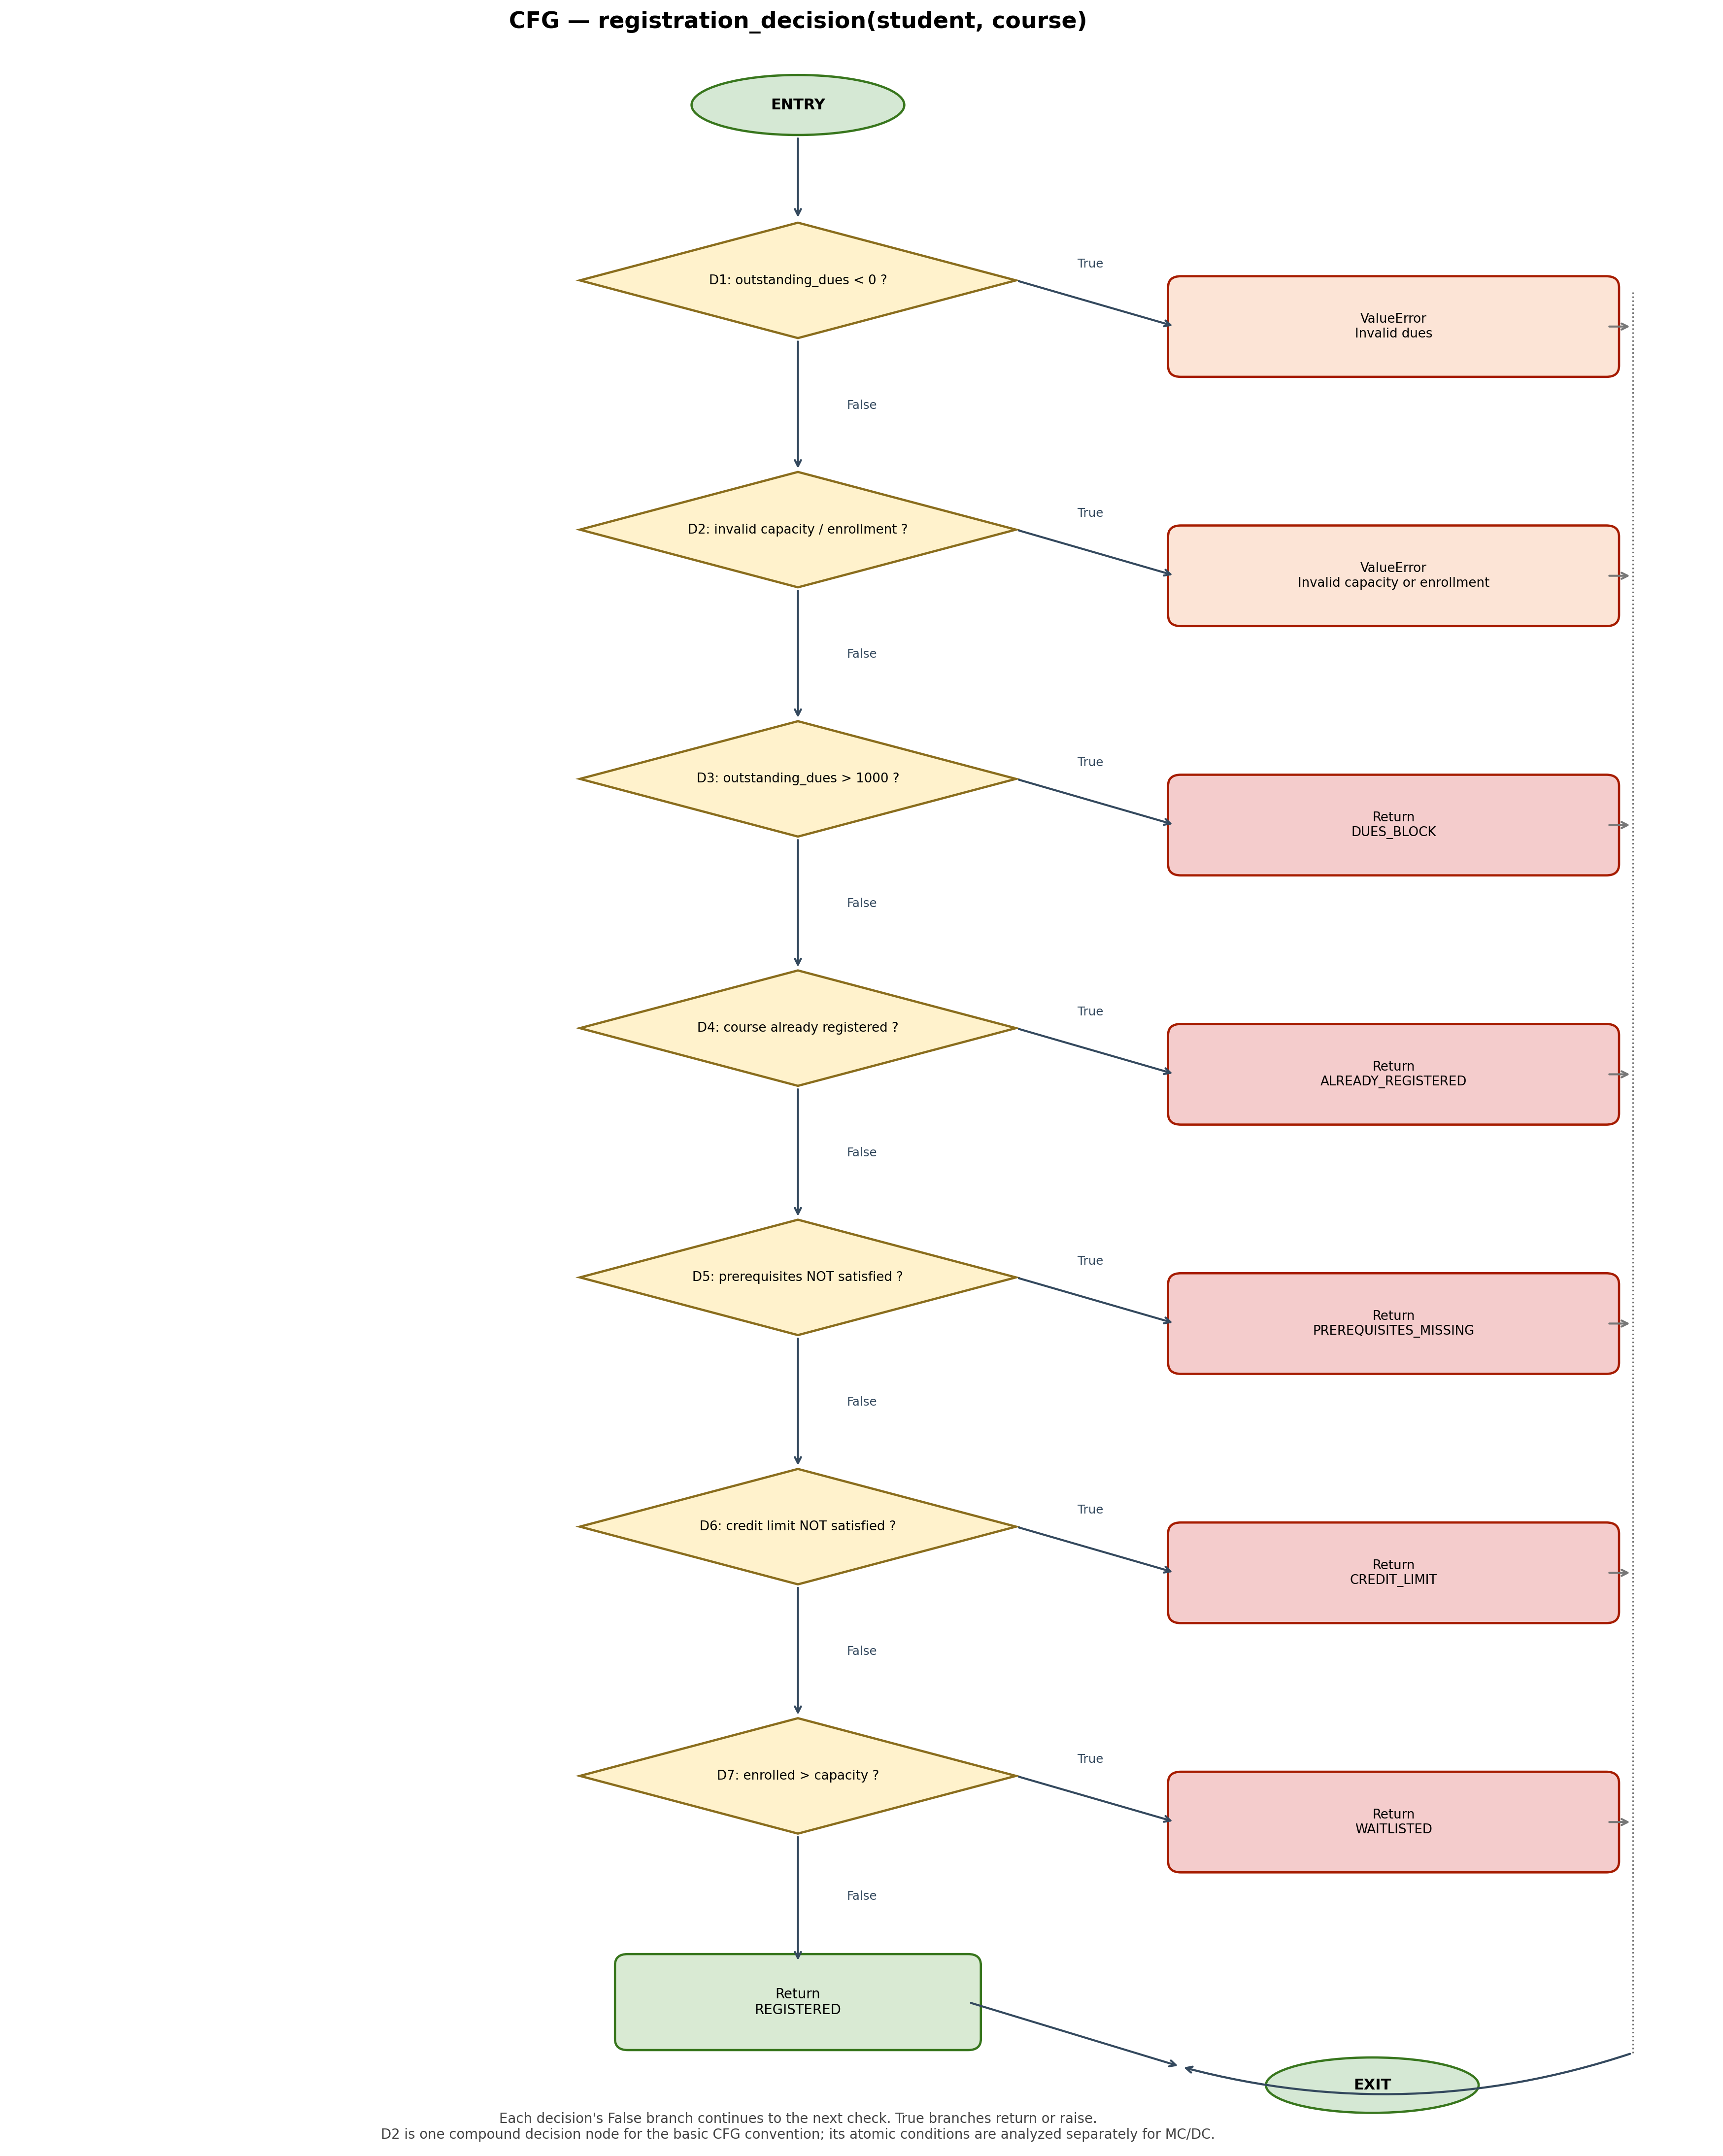

In [64]:
from IPython.display import Image, display

display(Image(filename="docs/registration_decision_cfg.png"))

In [65]:
%cd /home/heiwaaito/SQE-Assignment-2

report_path = "docs/B1_CFG_and_Basis_Paths.md"

with open(report_path, "r", encoding="utf-8") as file:
    content = file.read()

old_text = "The Control Flow Graph (CFG) for `registration_decision()` is saved separately. Insert the saved CFG image into this section of the final report."

new_text = """The Control Flow Graph (CFG) for `registration_decision()` is shown below.

![Control Flow Graph for registration_decision](registration_decision_cfg.png)"""

if old_text in content:
    content = content.replace(old_text, new_text)

    with open(report_path, "w", encoding="utf-8") as file:
        file.write(content)

    print("B1 report updated successfully!")
    print("CFG image embedded using a relative image link.")
else:
    print("The original instruction was not found. No changes were made.")

/home/heiwaaito/SQE-Assignment-2
B1 report updated successfully!
CFG image embedded using a relative image link.


In [66]:
%cd /home/heiwaaito/SQE-Assignment-2

import os

report_path = "docs/B1_CFG_and_Basis_Paths.md"
image_path = "docs/registration_decision_cfg.png"

print("B1 REPORT EXISTS:", os.path.exists(report_path))
print("CFG IMAGE EXISTS:", os.path.exists(image_path))

print("\nCFG IMAGE LINK IN REPORT:\n")

with open(report_path, "r", encoding="utf-8") as file:
    content = file.read()

for line in content.splitlines():
    if "registration_decision_cfg.png" in line:
        print(line)

/home/heiwaaito/SQE-Assignment-2
B1 REPORT EXISTS: True
CFG IMAGE EXISTS: True

CFG IMAGE LINK IN REPORT:

![Control Flow Graph for registration_decision](registration_decision_cfg.png)


In [67]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("docs/B1_CFG_and_Basis_Paths.md", "r", encoding="utf-8") as file:
    for line in file:
        if "registration_decision_cfg.png" in line:
            print(repr(line))

/home/heiwaaito/SQE-Assignment-2
'![Control Flow Graph for registration_decision](registration_decision_cfg.png)\n'


In [68]:
%cd /home/heiwaaito/SQE-Assignment-2

report_path = "docs/B1_CFG_and_Basis_Paths.md"

with open(report_path, "r", encoding="utf-8") as file:
    content = file.read()

content = content.replace("\\(", "(").replace("\\)", ")")

with open(report_path, "w", encoding="utf-8") as file:
    file.write(content)

print("Markdown image link corrected!")



/home/heiwaaito/SQE-Assignment-2
Markdown image link corrected!


In [69]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("docs/B1_CFG_and_Basis_Paths.md", "r", encoding="utf-8") as file:
    for line in file:
        if "registration_decision_cfg.png" in line:
            print(repr(line))

/home/heiwaaito/SQE-Assignment-2
'![Control Flow Graph for registration_decision](registration_decision_cfg.png)\n'


In [70]:
%cd /home/heiwaaito/SQE-Assignment-2

report_path = "docs/B1_CFG_and_Basis_Paths.md"

with open(report_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "registration_decision_cfg.png" in line:
        lines[i] = "![Control Flow Graph for registration_decision](registration_decision_cfg.png)\n"

with open(report_path, "w", encoding="utf-8") as file:
    file.writelines(lines)

print("Corrected image link:")
print(repr(lines[i]))

/home/heiwaaito/SQE-Assignment-2
Corrected image link:
'\n'


In [71]:
%cd /home/heiwaaito/SQE-Assignment-2

report_path = "docs/B1_CFG_and_Basis_Paths.md"

with open(report_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

found = False

for i, line in enumerate(lines):
    if "registration_decision_cfg.png" in line:
        lines[i] = "![Control Flow Graph for registration_decision](registration_decision_cfg.png)\n"
        found = True
        break

if found:
    with open(report_path, "w", encoding="utf-8") as file:
        file.writelines(lines)

    print("Corrected image link:")
    print(repr(lines[i]))
else:
    print("Image link not found. No changes made.")

/home/heiwaaito/SQE-Assignment-2
Corrected image link:
'![Control Flow Graph for registration_decision](registration_decision_cfg.png)\n'


In [72]:
%cd /home/heiwaaito/SQE-Assignment-2

report_path = "docs/B1_CFG_and_Basis_Paths.md"

correct_link = (
    "![Control Flow Graph for registration_decision]"
    + chr(40)
    + "registration_decision_cfg.png"
    + chr(41)
    + "\n"
)

with open(report_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

for i, line in enumerate(lines):
    if "registration_decision_cfg.png" in line:
        lines[i] = correct_link
        break

with open(report_path, "w", encoding="utf-8") as file:
    file.writelines(lines)

print("FINAL IMAGE LINK:")
print(lines[i])
print("BACKSLASH PRESENT:", chr(92) in lines[i])

/home/heiwaaito/SQE-Assignment-2
FINAL IMAGE LINK:
![Control Flow Graph for registration_decision](registration_decision_cfg.png)

BACKSLASH PRESENT: False


In [73]:
%cd /home/heiwaaito/SQE-Assignment-2

with open("docs/B1_CFG_and_Basis_Paths.md", "r", encoding="utf-8") as file:
    content = file.read()

for line in content.splitlines():
    if "registration_decision_cfg.png" in line:
        print(line)
        print("Backslash present:", chr(92) in line)
        print("Image file exists:", __import__("os").path.exists(
            "docs/registration_decision_cfg.png"
        ))

/home/heiwaaito/SQE-Assignment-2
![Control Flow Graph for registration_decision](registration_decision_cfg.png)
Backslash present: False
Image file exists: True
